# Problem komiwojażera (brute force)

**Uczenie głębokie – zadanie 1** · Adam Unrath

Szukamy najkrótszej trasy, która zaczyna się w Gdańsku, odwiedza każde z pozostałych miast dokładnie raz i wraca do Gdańska.

**Plan notebooka:**
1. Dane: miasta i macierz odległości
2. Algorytm: przeszukanie wszystkich permutacji (brute force)
3. Wynik
4. Wizualizacja: trasa na wykresie i porównanie wszystkich 24 tras

## 1. Dane

Kolejność wierszy i kolumn macierzy `odleglosci` odpowiada liście `miasta` (odległości w km).

In [1]:
from itertools import permutations

import matplotlib.pyplot as plt

miasta = ["Gdańsk", "Warszawa", "Kraków", "Wrocław", "Poznań"]

# Kolejność wierszy i kolumn odpowiada liście miast.
odleglosci = [
    [  0, 340, 600, 480, 300],  # Gdańsk
    [340,   0, 290, 350, 310],  # Warszawa
    [600, 290,   0, 270, 450],  # Kraków
    [480, 350, 270,   0, 180],  # Wrocław
    [300, 310, 450, 180,   0],  # Poznań
]

## 2. Algorytm

Gdańsk (indeks 0) jest stałym punktem startu i końca. Pozostałe 4 miasta ustawiamy we wszystkich możliwych kolejnościach, czyli 4! = 24 trasy. Dla każdej trasy sumujemy odległości między kolejnymi miastami i zapamiętujemy najkrótszą.

In [2]:
start = 0  # Indeks Gdańska na liście miast
pozostale = [1, 2, 3, 4]
najkrotsza_dlugosc = float("inf")  # Nieskończoność
najlepsza_trasa = None
liczba_tras = 0
wszystkie_trasy = []  # do wykresu porównawczego

# Sprawdzamy wszystkie kolejności pozostałych miast.
for kolejnosc in permutations(pozostale):
    trasa = [start] + list(kolejnosc) + [start]
    dlugosc = 0

    # Sumujemy odległości między kolejnymi miastami.
    for i in range(len(trasa) - 1):
        skad = trasa[i]
        dokad = trasa[i + 1]
        dlugosc += odleglosci[skad][dokad]

    wszystkie_trasy.append((trasa, dlugosc))

    # Zapamiętujemy lepsze rozwiązanie.
    if dlugosc < najkrotsza_dlugosc:
        najkrotsza_dlugosc = dlugosc
        najlepsza_trasa = trasa

    liczba_tras += 1

## 3. Wynik

In [3]:
nazwy_miast = [miasta[i] for i in najlepsza_trasa]
print("Najlepsza trasa:", " -> ".join(nazwy_miast))
print("Długość:", najkrotsza_dlugosc, "km")
print("Liczba sprawdzonych tras:", liczba_tras)

Najlepsza trasa: Gdańsk -> Warszawa -> Kraków -> Wrocław -> Poznań -> Gdańsk
Długość: 1380 km
Liczba sprawdzonych tras: 24


## 4. Wizualizacja

### 4.1 Najlepsza trasa na wykresie

Macierz zawiera tylko odległości, więc do narysowania mapy używamy przybliżonych współrzędnych geograficznych miast (długość, szerokość). Wykres ma charakter poglądowy.

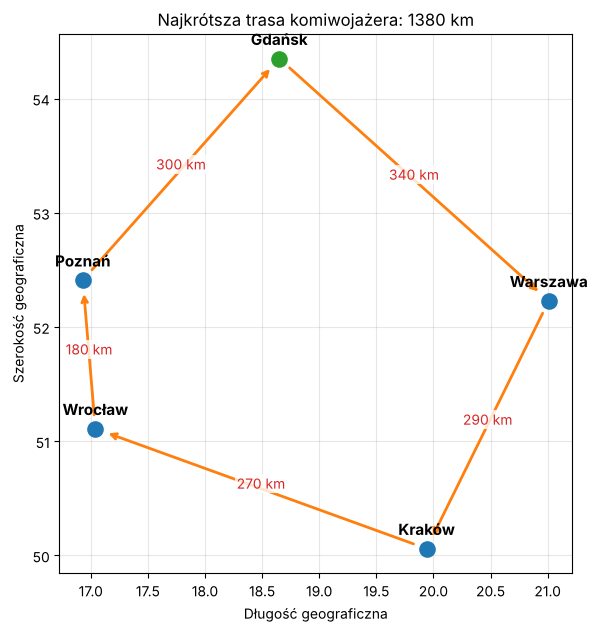

In [4]:
# Przybliżone współrzędne (długość geogr., szerokość geogr.) – tylko do rysunku
wspolrzedne = {
    "Gdańsk":   (18.65, 54.35),
    "Warszawa": (21.01, 52.23),
    "Kraków":   (19.94, 50.06),
    "Wrocław":  (17.04, 51.11),
    "Poznań":   (16.93, 52.41),
}

fig, ax = plt.subplots(figsize=(7, 7))

# Strzałki między kolejnymi miastami trasy z podpisem odległości
for i in range(len(najlepsza_trasa) - 1):
    a, b = najlepsza_trasa[i], najlepsza_trasa[i + 1]
    x1, y1 = wspolrzedne[miasta[a]]
    x2, y2 = wspolrzedne[miasta[b]]
    ax.annotate("", xy=(x2, y2), xytext=(x1, y1),
                arrowprops=dict(arrowstyle="->", color="tab:orange", lw=2,
                                shrinkA=10, shrinkB=10))
    ax.text((x1 + x2) / 2, (y1 + y2) / 2, f"{odleglosci[a][b]} km",
            fontsize=10, color="tab:red", ha="center",
            bbox=dict(facecolor="white", edgecolor="none", alpha=0.8, pad=1))

# Miasta
for nazwa, (x, y) in wspolrzedne.items():
    kolor = "tab:green" if nazwa == "Gdańsk" else "tab:blue"
    ax.scatter(x, y, s=120, color=kolor, zorder=3)
    ax.text(x, y + 0.12, nazwa, ha="center", fontsize=11, fontweight="bold")

ax.set_title(f"Najkrótsza trasa komiwojażera: {najkrotsza_dlugosc} km")
ax.set_xlabel("Długość geograficzna")
ax.set_ylabel("Szerokość geograficzna")
ax.set_aspect("equal")
ax.grid(alpha=0.3)
plt.show()

### 4.2 Porównanie wszystkich 24 tras

Słupek najkrótszej trasy jest wyróżniony kolorem.

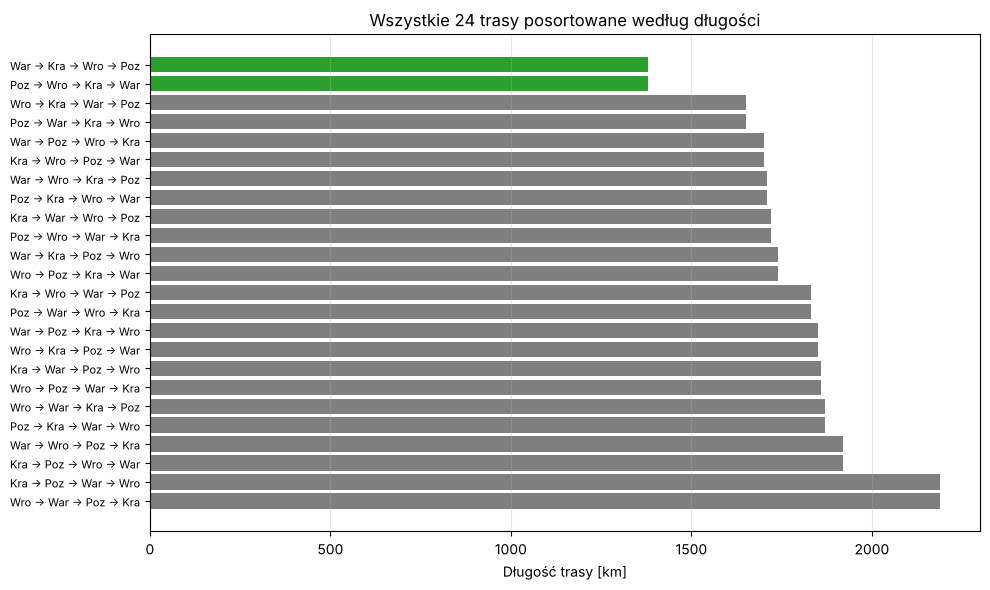

In [5]:
posortowane = sorted(wszystkie_trasy, key=lambda t: t[1])
etykiety = [" → ".join(miasta[i][:3] for i in t[0][1:-1]) for t in posortowane]
dlugosci = [t[1] for t in posortowane]
kolory = ["tab:green" if d == najkrotsza_dlugosc else "tab:gray" for d in dlugosci]

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(range(len(dlugosci)), dlugosci, color=kolory)
ax.set_yticks(range(len(dlugosci)))
ax.set_yticklabels(etykiety, fontsize=8)
ax.invert_yaxis()
ax.set_xlabel("Długość trasy [km]")
ax.set_title("Wszystkie 24 trasy posortowane według długości")
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

## 5. Wnioski

- Najkrótsza trasa ma **1380 km**: Gdańsk → Warszawa → Kraków → Wrocław → Poznań → Gdańsk.
- Na wykresie 4.2 dwie trasy mają tę samą najmniejszą długość: to ta sama pętla przejechana w przeciwnych kierunkach (macierz odległości jest symetryczna). Program zapamiętuje pierwszą z nich.
- Brute force sprawdza **(n−1)!** tras, więc dla 5 miast to tylko 24, ale liczba obliczeń rośnie bardzo szybko (dla 15 miast byłoby to już ponad 87 miliardów).
- Dla większej liczby miast stosuje się metody przybliżone (heurystyki, algorytmy genetyczne, uczenie ze wzmocnieniem).